# Dibuja y aprende — Paso 3: el dibujo como secuencia (RNN y LSTM)

Hasta ahora los modelos vieron el **dibujo terminado** (una imagen). Pero un dibujo también es una **secuencia**: los trazos se hacen uno tras otro, en orden. Eso es justo lo que procesan las RNN (clase del 19 de noviembre).

Cada dibujo es una secuencia de hasta 128 pasos. En cada paso: cuánto se movió el lápiz (dx, dy), si ahí terminó un trazo, y una marca de que el paso existe (el relleno se ignora con `Masking`).

Problema **many to one**: entra la secuencia completa y sale una palabra.

**Preguntas:**
1. ¿Una RNN simple puede con secuencias de 128 pasos, o le pasa lo del gradiente que desaparece?
2. ¿La LSTM le gana a la CNN, que solo ve el dibujo terminado?
3. ¿Puede adivinar **antes** de que la persona termine de dibujar?

> Nota: en clase la RNN se programó en PyTorch; aquí se usa Keras para mantener todo el proyecto en el mismo marco (y la misma forma de guardar el modelo).

In [1]:
import os, json, time, shutil
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
keras.utils.set_random_seed(SEED)

BASE = Path("/content")
DRIVE = Path("/content/drive/MyDrive/proyecto_dibujos")
USAR_DRIVE = True
if USAR_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    for archivo in ["dibujos_datos.npz", "palabras.json"]:
        if not (BASE / archivo).exists():
            shutil.copy(DRIVE / archivo, BASE / archivo)

datos = np.load(BASE / "dibujos_datos.npz")
PALABRAS = json.load(open(BASE / "palabras.json", encoding="utf-8"))
CLASES = list(PALABRAS); N = len(CLASES)

S = {k: datos[f"S_{k}"].astype(np.float32) for k in ["train", "val", "test", "no_reconocidos", "colombia"]}
Y = {k: datos[f"y_{k}"] for k in ["train", "val", "test", "no_reconocidos", "colombia"]}
col_reco = datos["colombia_reconocido"]
PASOS = S["train"].shape[1]
print({k: v.shape for k, v in S.items()})
print("GPU:", tf.config.list_physical_devices("GPU"))

EPOCAS = 20

Mounted at /content/drive
{'train': (224000, 128, 4), 'val': (48000, 128, 4), 'test': (48000, 128, 4), 'no_reconocidos': (40000, 128, 4), 'colombia': (7732, 128, 4)}
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


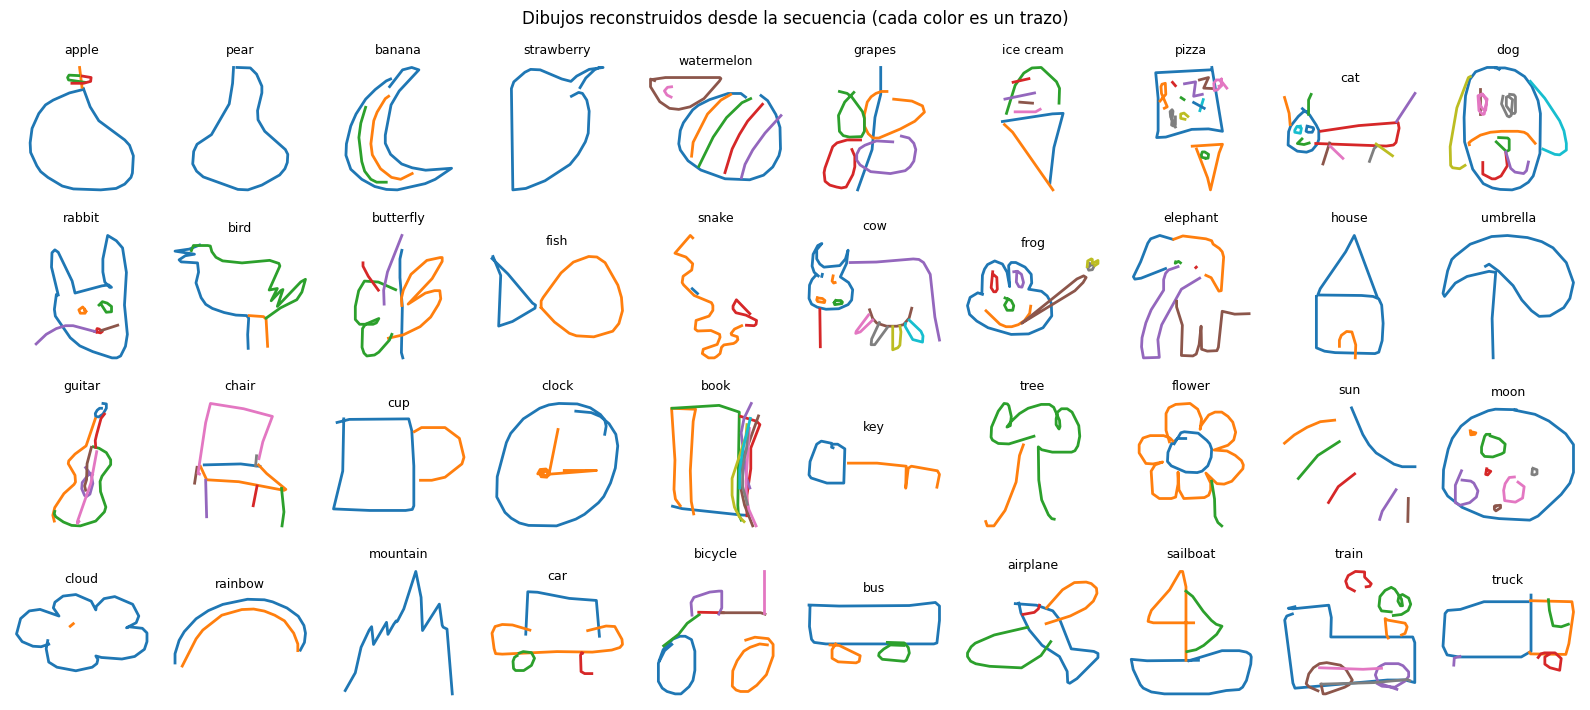

In [2]:
# Cómo se ve una secuencia: reconstruimos el dibujo a partir de los movimientos
def reconstruir(seq):
    activos = seq[seq[:, 3] > 0]
    pos = np.cumsum(activos[:, :2], axis=0)
    trazos, actual = [], []
    for (x, y_), fin in zip(pos, activos[:, 2]):
        actual.append((x, y_))
        if fin > 0.5:
            trazos.append(actual); actual = []
    if actual: trazos.append(actual)
    return trazos

filas = int(np.ceil(N / 10))
fig, axes = plt.subplots(filas, 10, figsize=(16, 1.8 * filas))
for ax in axes.flat: ax.axis("off")
for i, ax in enumerate(axes.flat[:N]):
    j = np.where(Y["train"] == i)[0][0]
    for t in reconstruir(S["train"][j]):
        t = np.array(t); ax.plot(t[:, 0], -t[:, 1], lw=2)
    ax.set_title(CLASES[i], fontsize=9); ax.axis("off"); ax.set_aspect("equal")
plt.suptitle("Dibujos reconstruidos desde la secuencia (cada color es un trazo)"); plt.tight_layout(); plt.show()

In [3]:
def callbacks():
    return [keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True),
            keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2)]

resultados = []
def entrenar_y_evaluar(modelo, nombre, idx=None, epocas=EPOCAS):
    Xtr, ytr = (S["train"], Y["train"]) if idx is None else (S["train"][idx], Y["train"][idx])
    modelo.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    t0 = time.time()
    hist = modelo.fit(Xtr, ytr, validation_data=(S["val"], Y["val"]), epochs=epocas, batch_size=256,
                      callbacks=callbacks(), verbose=2)
    seg = time.time() - t0
    p = modelo.predict(S["test"], batch_size=512, verbose=0).argmax(1)
    resultados.append({"modelo": nombre, "accuracy": accuracy_score(Y["test"], p),
                       "F1 macro": f1_score(Y["test"], p, average="macro"),
                       "parámetros": modelo.count_params(), "entrenamiento (s)": round(seg, 1)})
    print(resultados[-1])
    return hist

def curvas(hist, titulo):
    h = pd.DataFrame(hist.history)
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
    h[["loss", "val_loss"]].plot(ax=ax[0], title=f"{titulo} — pérdida")
    h[["accuracy", "val_accuracy"]].plot(ax=ax[1], title=f"{titulo} — accuracy")
    for a in ax: a.grid(True); a.set_xlabel("época")
    plt.tight_layout(); plt.show()

## 1. RNN simple

La misma idea de la clase: $h^{(t)} = \tanh(W_{xh}x^{(t)} + W_{hh}h^{(t-1)} + b)$, recorriendo los 128 pasos. Se entrena con 2.000 dibujos por palabra porque es lenta (no usa la versión optimizada de GPU).

Epoch 1/10
313/313 - 12s - 40ms/step - accuracy: 0.1207 - loss: 3.1964 - val_accuracy: 0.1765 - val_loss: 2.9494 - learning_rate: 0.0010
Epoch 2/10
313/313 - 5s - 15ms/step - accuracy: 0.2021 - loss: 2.8374 - val_accuracy: 0.2288 - val_loss: 2.7093 - learning_rate: 0.0010
Epoch 3/10
313/313 - 5s - 15ms/step - accuracy: 0.2335 - loss: 2.7097 - val_accuracy: 0.2428 - val_loss: 2.6514 - learning_rate: 0.0010
Epoch 4/10
313/313 - 5s - 16ms/step - accuracy: 0.2204 - loss: 2.7875 - val_accuracy: 0.2025 - val_loss: 2.8479 - learning_rate: 0.0010
Epoch 5/10
313/313 - 5s - 15ms/step - accuracy: 0.2452 - loss: 2.6821 - val_accuracy: 0.2804 - val_loss: 2.5619 - learning_rate: 0.0010
Epoch 6/10
313/313 - 5s - 15ms/step - accuracy: 0.2866 - loss: 2.5155 - val_accuracy: 0.3031 - val_loss: 2.4669 - learning_rate: 0.0010
Epoch 7/10
313/313 - 5s - 16ms/step - accuracy: 0.2981 - loss: 2.4799 - val_accuracy: 0.2859 - val_loss: 2.5318 - learning_rate: 0.0010
Epoch 8/10
313/313 - 10s - 32ms/step - accuracy

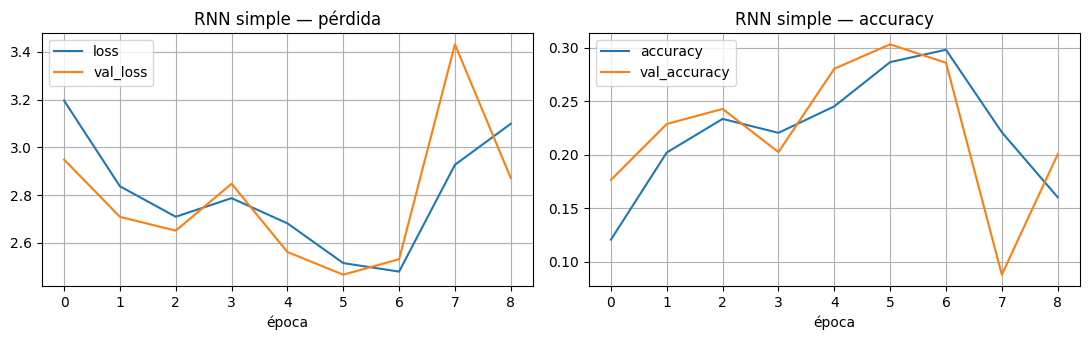

In [4]:
rng = np.random.default_rng(SEED)
sub = np.concatenate([rng.choice(np.where(Y["train"] == c)[0], min(2000, (Y["train"] == c).sum()), replace=False) for c in range(N)])

rnn = keras.Sequential([
    keras.Input((PASOS, 4)),
    layers.Masking(mask_value=0.0),
    layers.SimpleRNN(128),
    layers.Dense(N, activation="softmax"),
], name="RNN_simple")
hist_rnn = entrenar_y_evaluar(rnn, "RNN simple", idx=sub, epocas=max(1, EPOCAS // 2))
curvas(hist_rnn, "RNN simple")

## 2. LSTM

Las compuertas de la LSTM deciden qué recordar y qué olvidar, lo que evita que el gradiente desaparezca en secuencias largas. Dos capas: la primera devuelve toda la secuencia a la segunda.

Model: "LSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ masking_1 (Masking)             │ (None, 128, 4)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 128, 128)       │        68,096 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 128)            │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 40)             │         5,160 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 204,840 (800.16 KB)

 Trainable params: 204,840 (800.16 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
875/875 - 25s - 29ms/step - accuracy: 0.2974 - loss: 2.4980 - val_accuracy: 0.4814 - val_loss: 1.7839 - learning_rate: 0.0010
Epoch 2/20
875/875 - 36s - 41ms/step - accuracy: 0.5587 - loss: 1.5104 - val_accuracy: 0.6534 - val_loss: 1.1658 - learning_rate: 0.0010
Epoch 3/20
875/875 - 19s - 21ms/step - accuracy: 0.6779 - loss: 1.0874 - val_accuracy: 0.7368 - val_loss: 0.8637 - learning_rate: 0.0010
Epoch 4/20
875/875 - 18s - 21ms/step - accuracy: 0.7472 - loss: 0.8424 - val_accuracy: 0.7875 - val_loss: 0.6975 - learning_rate: 0.0010
Epoch 5/20
875/875 - 19s - 22ms/step - accuracy: 0.7899 - loss: 0.6937 - val_accuracy: 0.8136 - val_loss: 0.6096 - learning_rate: 0.0010
Epoch 6/20
875/875 - 19s - 21ms/step - accuracy: 0.8192 - loss: 0.5935 - val_accuracy: 0.8357 - val_loss: 0.5301 - learning_rate: 0.0010
Epoch 7/20
875/875 - 18s - 21ms/step - accuracy: 0.8402 - loss: 0.5227 - val_accuracy: 0.8480 - val_loss: 0.4934 - learning_rate: 0.0010
Epoch 8/20
875/875 - 22s - 25ms/step - ac

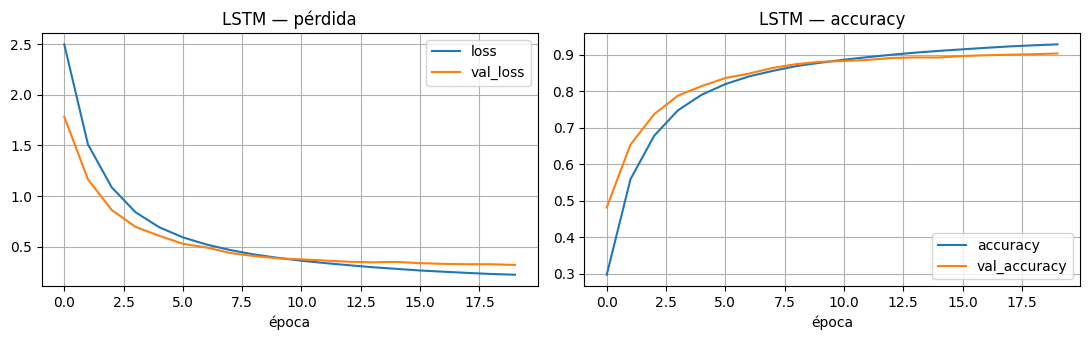

In [5]:
lstm = keras.Sequential([
    keras.Input((PASOS, 4)),
    layers.Masking(mask_value=0.0),
    layers.LSTM(128, return_sequences=True),
    layers.LSTM(128),
    layers.Dropout(0.3),
    layers.Dense(N, activation="softmax"),
], name="LSTM")
lstm.summary()
hist_lstm = entrenar_y_evaluar(lstm, "LSTM")
curvas(hist_lstm, "LSTM")

## 3. Comparación con los modelos de imagen (paso 2)

,accuracy,F1 macro,parámetros,entrenamiento (s)
modelo,,,,
0. Azar,0.025,0.025,—,—
RNN simple,0.301,0.269,22184.000000,56.200000
1. SVM linear,0.596,0.596,—,36.900000
1. Random Forest,0.633,0.617,—,77.400000
1. SVM poly,0.726,0.725,—,27.400000
1. SVM rbf,0.736,0.736,—,22.900000
2. ANN,0.779,0.777,239016.000000,171.700000
4. MobileNetV2 TL,0.891,0.891,2309224.000000,922.500000
LSTM,0.903,0.903,204840.000000,403.900000


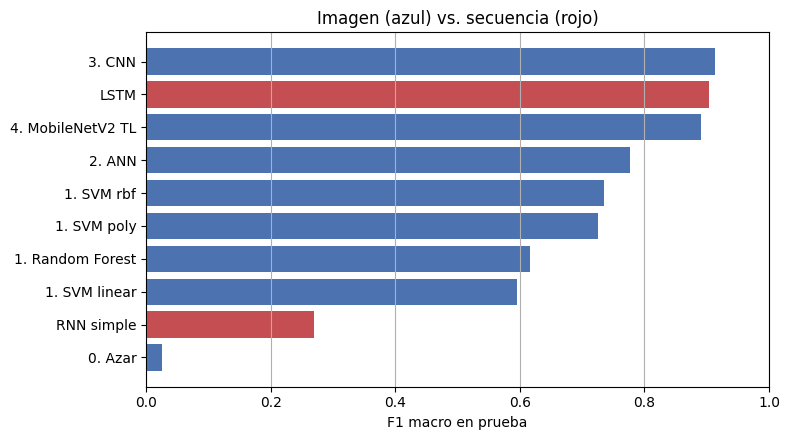

In [6]:
tabla = pd.DataFrame(resultados).set_index("modelo")
ruta_p2 = (DRIVE if USAR_DRIVE else BASE) / "modelo_app" / "comparacion_modelos.csv"
if ruta_p2.exists():
    p2 = pd.read_csv(ruta_p2, index_col=0)[["accuracy", "F1 macro", "parámetros", "entrenamiento (s)"]]
    tabla = pd.concat([p2, tabla])
tabla = tabla.sort_values("F1 macro")
display(tabla.style.format({"accuracy": "{:.3f}", "F1 macro": "{:.3f}"}, na_rep="—"))

plt.figure(figsize=(8, 4.5))
plt.barh(tabla.index, tabla["F1 macro"], color=["#C44E52" if i in ("RNN simple", "LSTM") else "#4C72B0" for i in tabla.index])
plt.xlim(0, 1); plt.xlabel("F1 macro en prueba"); plt.grid(axis="x")
plt.title("Imagen (azul) vs. secuencia (rojo)"); plt.tight_layout(); plt.show()

## 4. Pruebas difíciles con la LSTM

In [7]:
filas = []
for nom, X_, y_ in [("prueba normal", S["test"], Y["test"]),
                    ("no reconocidos", S["no_reconocidos"], Y["no_reconocidos"]),
                    ("Colombia (reconocidos)", S["colombia"][col_reco], Y["colombia"][col_reco]),
                    ("Colombia (no reconocidos)", S["colombia"][~col_reco], Y["colombia"][~col_reco])]:
    if len(y_):
        p = lstm.predict(X_, batch_size=512, verbose=0).argmax(1)
        filas.append({"conjunto": nom, "dibujos": len(y_), "accuracy LSTM": accuracy_score(y_, p)})
pd.DataFrame(filas).set_index("conjunto").style.format({"accuracy LSTM": "{:.3f}"})

,dibujos,accuracy LSTM
conjunto,,
prueba normal,48000,0.903
no reconocidos,40000,0.406
Colombia (reconocidos),7219,0.908
Colombia (no reconocidos),513,0.423


## 5. ¿Adivina antes de que termines?

Se le muestra a la LSTM solo el **comienzo** del dibujo (25 %, 50 %, 75 % de los puntos) y se mira cuánto acierta. Es lo que hace el juego de Google: adivinar mientras dibujas.

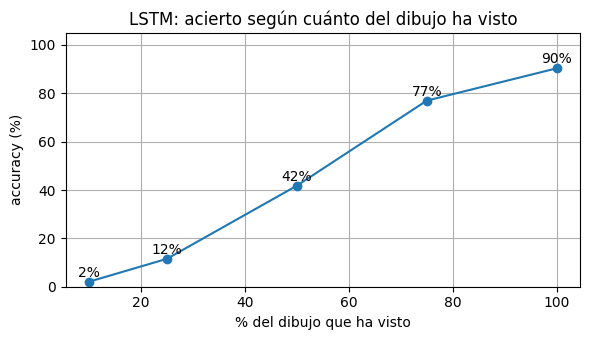

In [8]:
def recortar(Sx, fraccion):
    out = Sx.copy()
    largos = (Sx[:, :, 3] > 0).sum(1)
    for i, L in enumerate(largos):
        k = max(1, int(np.ceil(L * fraccion)))
        out[i, k:] = 0.0
    return out

fracciones = [0.1, 0.25, 0.5, 0.75, 1.0]
acc = [accuracy_score(Y["test"], lstm.predict(recortar(S["test"], f), batch_size=512, verbose=0).argmax(1)) for f in fracciones]
plt.figure(figsize=(6, 3.5))
plt.plot([100 * f for f in fracciones], [100 * a for a in acc], marker="o")
for f, a in zip(fracciones, acc):
    plt.text(100 * f, 100 * a + 2, f"{a:.0%}", ha="center")
plt.xlabel("% del dibujo que ha visto"); plt.ylabel("accuracy (%)"); plt.ylim(0, 105); plt.grid(True)
plt.title("LSTM: acierto según cuánto del dibujo ha visto"); plt.tight_layout(); plt.show()

In [9]:
CARPETA = BASE / "modelo_lstm"; CARPETA.mkdir(exist_ok=True)
lstm.save(CARPETA / "modelo_lstm.keras")
tabla.to_csv(CARPETA / "comparacion_imagen_vs_secuencia.csv")
if USAR_DRIVE:
    shutil.copytree(CARPETA, DRIVE / "modelo_lstm", dirs_exist_ok=True)
print("Guardado.")

Guardado.


## Resumen

*(Completar con los números de la ejecución.)*
- RNN simple: F1 ___ → ¿sufrió con 128 pasos?
- LSTM: F1 ___, frente a CNN ___.
- Con el 50 % del dibujo, la LSTM ya acierta ___ %.
- Conclusión: ___ (¿qué conviene para la app: imagen o secuencia, y por qué?).